# 🧪 Silica Gel Condition Classification & Outside Image Testing

This notebook builds, trains, validates, and deploys a deep learning model to classify silica gel condition based on chemical indicator color changes.

### 🎯 Objective & Class Mapping
The model classifies images across **6 Unified Classes**:
| Class ID | Target Label | Gel Type | Saturation Condition | Source Directory | Color Profile |
| :---: | :--- | :---: | :---: | :--- | :--- |
| **0** | `blue_unsaturated` | Blue | **Unsaturated** (Fresh / Dry) | `blue_silicagel/initial` | Deep Royal / Cobalt Blue |
| **1** | `blue_semi_saturated` | Blue | **Semi-Saturated** (Partially Absorbed) | `blue_silicagel/unsaturated` | Violet / Purple / Lavender |
| **2** | `blue_saturated` | Blue | **Saturated** (Exhausted) | `blue_silicagel/saturated` | Pink / Light Rose |
| **3** | `orange_unsaturated` | Orange | **Unsaturated** (Fresh / Dry) | `orange_silicagel/initial` | Bright Orange / Amber |
| **4** | `orange_semi_saturated` | Orange | **Semi-Saturated** (Partially Absorbed) | `orange_silicagel/unsaturated` | Olive / Yellow-Green |
| **5** | `orange_saturated` | Orange | **Saturated** (Exhausted) | `orange_silicagel/saturated` | Dark Green / Teal / Blackish |

---

### ⚙️ Protocol
- **Stratified Split**: **80% Training (240 samples)** and **20% Validation (60 samples)** — exactly 40 train and 10 val images per class.
- **Backbone**: Deep Residual Network (**ResNet50**) with pretrained ImageNet weights (and toggleable EfficientNet / Vision Transformer options).
- **Outside Image Testing**: Interactive image uploader and color-analyzer widget to test real-world images.


In [1]:
import os
import glob
import random
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Hardware Device: {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"GPU Accelerator: {torch.cuda.get_device_name(0)}")


Hardware Device: cuda
GPU Accelerator: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Dataset Indexing & Stratified 80/20 Split

We collect all 300 images across the 6 condition folders and perform a balanced, stratified 80% train / 20% validation split.


In [2]:
BASE_DIR = os.getcwd()

# Class definition dictionary
CLASS_DEFS = [
    {
        'id': 0,
        'name': 'blue_unsaturated',
        'gel': 'Blue',
        'condition': 'Unsaturated',
        'path': os.path.join(BASE_DIR, 'blue_silicagel', 'initial')
    },
    {
        'id': 1,
        'name': 'blue_semi_saturated',
        'gel': 'Blue',
        'condition': 'Semi-Saturated',
        'path': os.path.join(BASE_DIR, 'blue_silicagel', 'unsaturated')
    },
    {
        'id': 2,
        'name': 'blue_saturated',
        'gel': 'Blue',
        'condition': 'Saturated',
        'path': os.path.join(BASE_DIR, 'blue_silicagel', 'saturated')
    },
    {
        'id': 3,
        'name': 'orange_unsaturated',
        'gel': 'Orange',
        'condition': 'Unsaturated',
        'path': os.path.join(BASE_DIR, 'orange_silicagel', 'initial')
    },
    {
        'id': 4,
        'name': 'orange_semi_saturated',
        'gel': 'Orange',
        'condition': 'Semi-Saturated',
        'path': os.path.join(BASE_DIR, 'orange_silicagel', 'unsaturated')
    },
    {
        'id': 5,
        'name': 'orange_saturated',
        'gel': 'Orange',
        'condition': 'Saturated',
        'path': os.path.join(BASE_DIR, 'orange_silicagel', 'saturated')
    }
]

CLASS_NAMES = [c['name'] for c in CLASS_DEFS]
CLASS_DISPLAY = [f"{c['gel']} - {c['condition']}" for c in CLASS_DEFS]

# Scan images
all_image_paths = []
all_labels = []

for c in CLASS_DEFS:
    pattern = os.path.join(c['path'], '*.*')
    files = [f for f in glob.glob(pattern) if f.lower().endswith(('.jpeg', '.jpg', '.png'))]
    for f in files:
        all_image_paths.append(f)
        all_labels.append(c['id'])

print(f"Total dataset indexed: {len(all_image_paths)} images across {len(CLASS_NAMES)} classes.")

# Stratified 80% Train, 20% Validation Split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_image_paths,
    all_labels,
    test_size=0.20,
    stratify=all_labels,
    random_state=SEED
)

print(f"\n{'Class ID':<8} | {'Class Name':<24} | {'Train (80%)':<12} | {'Val (20%)':<10} | {'Total':<6}")
print("-" * 70)
for c in CLASS_DEFS:
    n_train = sum(1 for y in train_labels if y == c['id'])
    n_val = sum(1 for y in val_labels if y == c['id'])
    print(f"{c['id']:<8} | {c['name']:<24} | {n_train:<12} | {n_val:<10} | {n_train + n_val:<6}")
print("-" * 70)
print(f"{'Total':<8} | {'All Classes':<24} | {len(train_labels):<12} | {len(val_labels):<10} | {len(all_labels):<6}")


Total dataset indexed: 300 images across 6 classes.

Class ID | Class Name               | Train (80%)  | Val (20%)  | Total 
----------------------------------------------------------------------
0        | blue_unsaturated         | 40           | 10         | 50    
1        | blue_semi_saturated      | 40           | 10         | 50    
2        | blue_saturated           | 40           | 10         | 50    
3        | orange_unsaturated       | 40           | 10         | 50    
4        | orange_semi_saturated    | 40           | 10         | 50    
5        | orange_saturated         | 40           | 10         | 50    
----------------------------------------------------------------------
Total    | All Classes              | 240          | 60         | 300   


## 2. Transforms & DataLoaders

- **Train Transforms**: Resize to $224 \times 224$, flips, rotation, mild brightness/contrast jitter with **Hue locked to 0.0**, ImageNet normalization.
- **Val Transforms**: Resize to $224 \times 224$, ImageNet normalization.


In [3]:
# Normalization standards for ImageNet pre-trained backbones
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

train_transforms = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=180),
    T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05, hue=0.0),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

class SilicaGelDataset(Dataset):
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        path = self.file_paths[idx]
        image = Image.open(path).convert('RGB')
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
            
        return image, label, path

train_dataset = SilicaGelDataset(train_paths, train_labels, transform=train_transforms)
val_dataset = SilicaGelDataset(val_paths, val_labels, transform=val_transforms)

BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train batches per epoch: {len(train_loader)} (Batch size: {BATCH_SIZE})")
print(f"Validation batches per epoch: {len(val_loader)}")


Train batches per epoch: 15 (Batch size: 16)
Validation batches per epoch: 4


## 3. Model Architecture: Pretrained ResNet-50 Classifier

We instantiate a pretrained **ResNet-50** deep convolutional backbone and replace the final classification head with a custom linear projection for our 6 silica gel classes.


In [4]:
def build_silicagel_model(num_classes=6, dropout_p=0.3):
    # Pretrained ResNet50
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    
    # Replace final fully connected layer
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=dropout_p),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(p=dropout_p),
        nn.Linear(512, num_classes)
    )
    return model

model = build_silicagel_model(num_classes=6).to(DEVICE)
print(f"ResNet-50 loaded with custom 6-class head on {DEVICE}.")


ResNet-50 loaded with custom 6-class head on cuda.


## 4. Model Training & Validation Engine

We train the model using **AdamW** with weight decay and a **Cosine Annealing** learning rate scheduler.


In [5]:
NUM_EPOCHS = 15
LEARNING_RATE = 1e-4

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

best_val_acc = 0.0
best_model_weights = copy.deepcopy(model.state_dict())
start_time = time.time()

print(f"Starting training on {DEVICE} for {NUM_EPOCHS} epochs...")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):
    # Training phase
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for inputs, targets, _ in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == targets.data).item()
        total_train += targets.size(0)
        
    scheduler.step()
    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100.0
    
    # Validation phase
    model.eval()
    val_running_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for inputs, targets, _ in val_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            val_running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == targets.data).item()
            total_val += targets.size(0)
            
    epoch_val_loss = val_running_loss / total_val
    epoch_val_acc = (correct_val / total_val) * 100.0
    
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:5.1f}% | "
          f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:5.1f}%")
    
    # Save best model
    if epoch_val_acc >= best_val_acc:
        best_val_acc = epoch_val_acc
        best_model_weights = copy.deepcopy(model.state_dict())

elapsed = time.time() - start_time
print("=" * 70)
print(f"🎉 Training complete in {elapsed:.1f} seconds! Best Validation Accuracy: {best_val_acc:.2f}%")

# Load best weights & save to disk
model.load_state_dict(best_model_weights)
MODEL_SAVE_PATH = os.path.join(BASE_DIR, 'best_silicagel_model.pth')
torch.save({
    'model_state_dict': model.state_dict(),
    'class_defs': CLASS_DEFS,
    'class_names': CLASS_NAMES,
    'class_display': CLASS_DISPLAY,
    'best_val_acc': best_val_acc
}, MODEL_SAVE_PATH)
print(f"Best model weights saved to: {MODEL_SAVE_PATH}")


Starting training on cuda for 15 epochs...


Epoch 01/15 | Train Loss: 1.6813 - Train Acc:  43.8% | Val Loss: 1.4711 - Val Acc:  85.0%


Epoch 02/15 | Train Loss: 1.0883 - Train Acc:  82.5% | Val Loss: 0.6389 - Val Acc:  88.3%


Epoch 03/15 | Train Loss: 0.6368 - Train Acc:  87.5% | Val Loss: 0.4033 - Val Acc:  96.7%


Epoch 04/15 | Train Loss: 0.4285 - Train Acc:  93.8% | Val Loss: 0.3527 - Val Acc:  98.3%


Epoch 05/15 | Train Loss: 0.4013 - Train Acc:  94.2% | Val Loss: 0.3155 - Val Acc:  98.3%


... (6 outputs left out)

Epoch 12/15 | Train Loss: 0.3051 - Train Acc:  97.5% | Val Loss: 0.3228 - Val Acc:  95.0%


Epoch 13/15 | Train Loss: 0.2945 - Train Acc:  98.8% | Val Loss: 0.3230 - Val Acc:  95.0%


Epoch 14/15 | Train Loss: 0.2927 - Train Acc:  97.5% | Val Loss: 0.3251 - Val Acc:  95.0%


Epoch 15/15 | Train Loss: 0.3053 - Train Acc:  98.3% | Val Loss: 0.3253 - Val Acc:  95.0%
🎉 Training complete in 136.9 seconds! Best Validation Accuracy: 98.33%
Best model weights saved to: c:\Users\krish\OneDrive\Desktop\project_transformer\best_silicagel_model.pth


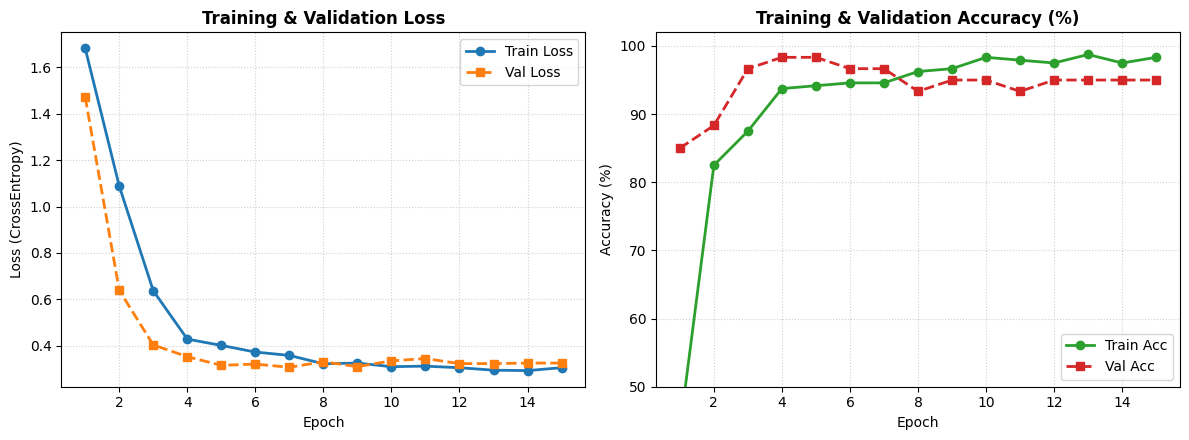

In [6]:
# Plot Training & Validation Curves
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(range(1, NUM_EPOCHS + 1), history['train_loss'], 'o-', label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(range(1, NUM_EPOCHS + 1), history['val_loss'], 's--', label='Val Loss', color='#ff7f0e', linewidth=2)
plt.title('Training & Validation Loss', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss (CrossEntropy)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, NUM_EPOCHS + 1), history['train_acc'], 'o-', label='Train Acc', color='#2ca02c', linewidth=2)
plt.plot(range(1, NUM_EPOCHS + 1), history['val_acc'], 's--', label='Val Acc', color='#d62728', linewidth=2)
plt.title('Training & Validation Accuracy (%)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.ylim(50, 102)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()


## 5. Evaluation & Confusion Matrix

Let's evaluate the trained model on the unseen 20% validation split (60 images) and generate a detailed classification report and confusion matrix.


Classification Report on 20% Validation Set:
                         precision    recall  f1-score   support

     Blue - Unsaturated     1.0000    1.0000    1.0000        10
  Blue - Semi-Saturated     1.0000    1.0000    1.0000        10
       Blue - Saturated     1.0000    1.0000    1.0000        10
   Orange - Unsaturated     1.0000    1.0000    1.0000        10
Orange - Semi-Saturated     0.9091    1.0000    0.9524        10
     Orange - Saturated     1.0000    0.9000    0.9474        10

               accuracy                         0.9833        60
              macro avg     0.9848    0.9833    0.9833        60
           weighted avg     0.9848    0.9833    0.9833        60



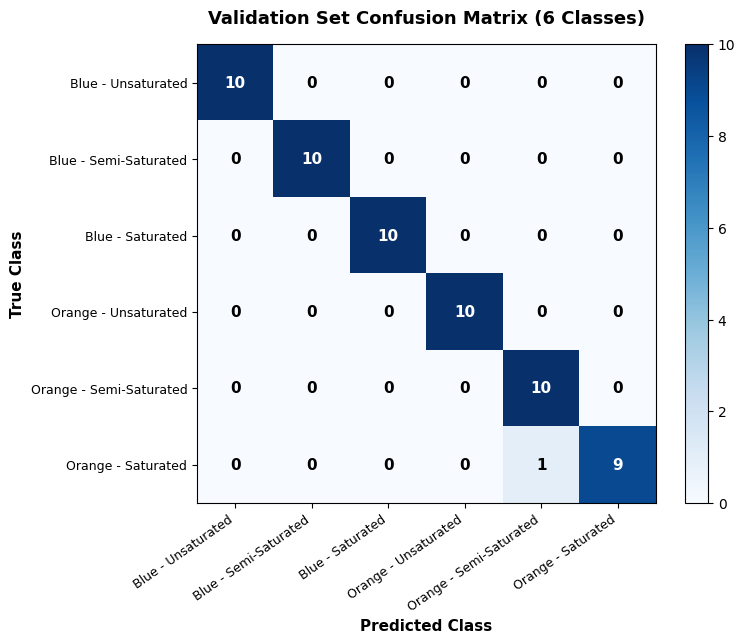

In [7]:
model.eval()
val_targets = []
val_predictions = []

with torch.no_grad():
    for inputs, targets, _ in val_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        val_targets.extend(targets.tolist())
        val_predictions.extend(preds.cpu().tolist())

# Classification Report
print("Classification Report on 20% Validation Set:")
print("=" * 65)
print(classification_report(val_targets, val_predictions, target_names=CLASS_DISPLAY, digits=4))
print("=" * 65)

# Confusion Matrix Heatmap
cm = confusion_matrix(val_targets, val_predictions)

plt.figure(figsize=(8, 6.5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Validation Set Confusion Matrix (6 Classes)', fontsize=13, fontweight='bold', pad=15)
plt.colorbar()
tick_marks = np.arange(len(CLASS_DISPLAY))
plt.xticks(tick_marks, CLASS_DISPLAY, rotation=35, ha='right', fontsize=9)
plt.yticks(tick_marks, CLASS_DISPLAY, fontsize=9)

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontweight='bold', fontsize=11)

plt.ylabel('True Class', fontsize=11, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Outside Image Testing & Color Analysis Pipeline

This section allows you to test **any outside image** (uploaded from computer or external path).
The pipeline:
1. Performs neural classification to predict:
   - **Gel Type**: Blue or Orange Silica Gel
   - **Condition**: Unsaturated, Semi-Saturated, or Saturated
   - **Confidence Score (%)**
2. Performs **Dominant Color Extraction & HSV Analysis**:
   - Calculates the average RGB and HSV color space values of the silica beads.
   - Shows the exact color swatch, explaining *why* the model made its decision.
3. Renders a bar plot displaying probabilities across all classes.


In [8]:
import colorsys

def analyze_image_color(pil_img):
    """Calculates dominant/mean color and HSV properties."""
    img_rgb = pil_img.convert('RGB')
    arr = np.array(img_rgb)
    mean_rgb = arr.mean(axis=(0, 1)).astype(int)
    r_norm, g_norm, b_norm = mean_rgb[0]/255.0, mean_rgb[1]/255.0, mean_rgb[2]/255.0
    h, s, v = colorsys.rgb_to_hsv(r_norm, g_norm, b_norm)
    return {
        'mean_rgb': tuple(mean_rgb),
        'hex': '#{:02x}{:02x}{:02x}'.format(mean_rgb[0], mean_rgb[1], mean_rgb[2]),
        'h_deg': round(h * 360, 1),
        's_pct': round(s * 100, 1),
        'v_pct': round(v * 100, 1)
    }

def predict_silica_gel(image_input, model=model, device=DEVICE):
    """
    Predicts silica gel type and saturation state for any input image.
    image_input: Can be a filepath (str) or a PIL Image object.
    """
    model.eval()
    if isinstance(image_input, str):
        if not os.path.exists(image_input):
            raise FileNotFoundError(f"Image not found at {image_input}")
        pil_img = Image.open(image_input).convert('RGB')
    elif isinstance(image_input, Image.Image):
        pil_img = image_input.convert('RGB')
    else:
        raise ValueError("image_input must be a filepath string or PIL.Image instance")
        
    # Preprocess
    tensor = val_transforms(pil_img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        logits = model(tensor)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
        pred_idx = int(np.argmax(probs))
        confidence = probs[pred_idx] * 100.0

    pred_def = CLASS_DEFS[pred_idx]
    color_info = analyze_image_color(pil_img)
    
    # Visualization
    fig = plt.figure(figsize=(14, 4.5))
    
    # 1. Input image
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.imshow(pil_img)
    ax1.set_title("Input Image", fontsize=11, fontweight='bold')
    ax1.axis('off')
    
    # 2. Extracted Color Swatch & Color Breakdown
    ax2 = fig.add_subplot(1, 3, 2)
    swatch = np.full((100, 100, 3), color_info['mean_rgb'], dtype=np.uint8)
    ax2.imshow(swatch)
    ax2.set_title("Mean Color Swatch", fontsize=11, fontweight='bold')
    ax2.axis('off')
    text_desc = (
        f"Hex: {color_info['hex']}\n"
        f"RGB: {color_info['mean_rgb']}\n"
        f"Hue: {color_info['h_deg']}°\n"
        f"Saturation: {color_info['s_pct']}%\n"
        f"Brightness: {color_info['v_pct']}%"
    )
    ax2.text(50, 130, text_desc, ha='center', fontsize=10, family='monospace',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="#f0f0f0", edgecolor="#ccc"))
    ax2.set_ylim(160, -10)
    
    # 3. Probability Distribution Bar Chart
    ax3 = fig.add_subplot(1, 3, 3)
    bar_colors = ['#1f77b4' if 'blue' in name else '#ff7f0e' for name in CLASS_NAMES]
    y_pos = np.arange(len(CLASS_NAMES))
    bars = ax3.barh(y_pos, probs * 100.0, color=bar_colors, edgecolor='black', alpha=0.85)
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels(CLASS_DISPLAY, fontsize=9)
    ax3.invert_yaxis()
    ax3.set_xlabel('Probability (%)', fontsize=10)
    ax3.set_xlim(0, 100)
    ax3.grid(axis='x', linestyle=':', alpha=0.6)
    
    # Highlight top prediction
    bars[pred_idx].set_edgecolor('red')
    bars[pred_idx].set_linewidth(2.5)
    
    for bar in bars:
        w = bar.get_width()
        if w > 4:
            ax3.text(w + 1.5, bar.get_y() + bar.get_height()/2.0, f"{w:.1f}%", va='center', fontsize=9, fontweight='bold')
            
    ax3.set_title(f"Prediction: {pred_def['gel']} - {pred_def['condition']}\nConfidence: {confidence:.1f}%",
                  fontsize=11, fontweight='bold', color='darkgreen' if confidence > 80 else 'black')
    
    plt.tight_layout()
    plt.show()
    
    return {
        'gel_type': pred_def['gel'],
        'saturation_condition': pred_def['condition'],
        'predicted_class': pred_def['name'],
        'confidence_pct': round(confidence, 2),
        'probabilities': {name: round(float(p) * 100, 2) for name, p in zip(CLASS_NAMES, probs)},
        'color_analysis': color_info
    }


### 🧪 Test Run on Sample Validation Images
Let's run `predict_silica_gel` on sample validation images from both blue and orange silica gel to demonstrate the output.


Testing Blue Silica Gel Sample from Validation Set:


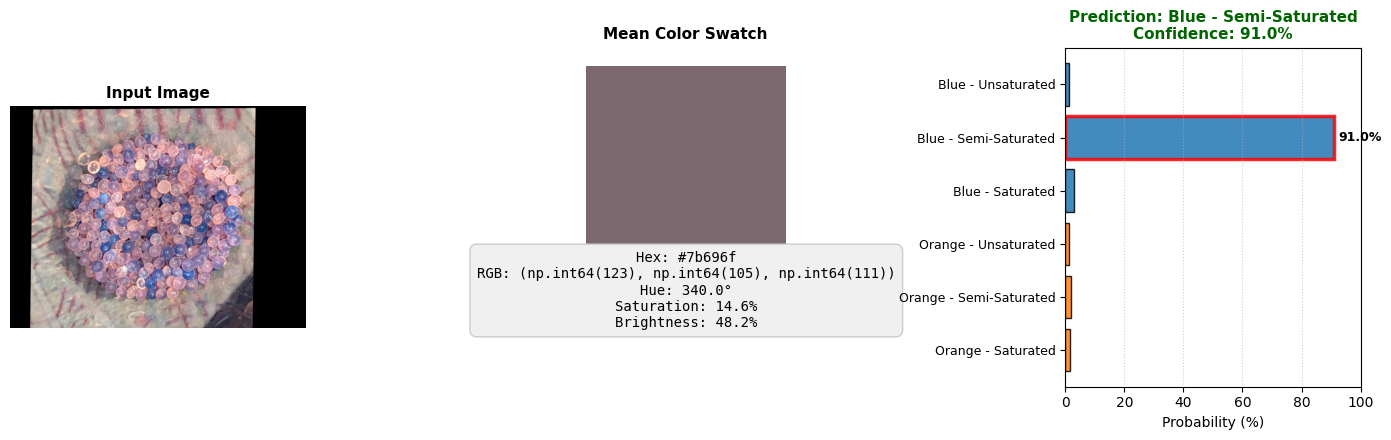


Testing Orange Silica Gel Sample from Validation Set:


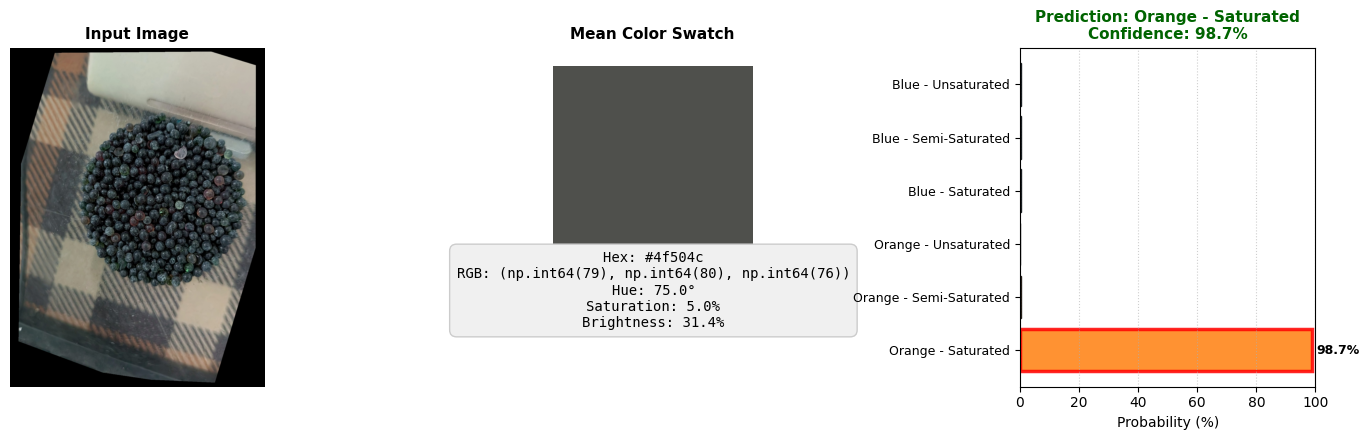

In [9]:
print("Testing Blue Silica Gel Sample from Validation Set:")
sample_blue = [p for p, l in zip(val_paths, val_labels) if l == 1][0] # blue semi-saturated
res1 = predict_silica_gel(sample_blue)

print("\nTesting Orange Silica Gel Sample from Validation Set:")
sample_orange = [p for p, l in zip(val_paths, val_labels) if l == 5][0] # orange saturated
res2 = predict_silica_gel(sample_orange)


### 📤 Interactive File Uploader for Outside Images

Click the button below to upload an outside photo of silica gel beads from your computer:


In [10]:
import io
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(
    accept='image/*',
    multiple=False,
    description='Upload Image'
)

out = widgets.Output()

def on_upload_change(change):
    with out:
        out.clear_output()
        if not uploader.value:
            return
        # Get uploaded content
        uploaded_file = list(uploader.value.values())[0] if isinstance(uploader.value, dict) else uploader.value[0]
        content = uploaded_file['content']
        img = Image.open(io.BytesIO(content))
        print("Image uploaded successfully! Running prediction...")
        result = predict_silica_gel(img)
        print(f"\nResult Summary:")
        print(f"   • Gel Type: {result['gel_type']}")
        print(f"   • Condition: {result['saturation_condition']}")
        print(f"   • Confidence: {result['confidence_pct']}%")

uploader.observe(on_upload_change, names='value')

print("👉 Use the widget below to test your own outside images:")
display(uploader)
display(out)


👉 Use the widget below to test your own outside images:


FileUpload(value=(), accept='image/*', description='Upload Image')

Output()